In [15]:
import pandas as pd
import numpy as np

import json

from pathlib import Path
cwd = Path.cwd()

In [2]:
model_number = 5
trial_number = 6

trial_dir = f"model_v{model_number}_test_{trial_number}"


DATA_DIR = cwd.parent / "test" / trial_dir
DATA_FILE = DATA_DIR / "test.csv"

In [3]:
df = pd.read_csv(DATA_FILE, low_memory=False)
df.head(5)

,epoch,train_bg_rmse,train_bg_mae,train_bg_r2,train_bg_r2-semi,train_fe_rmse,train_fe_mae,train_fe_r2,train_metal_acc,test_bg_rmse,test_bg_mae,test_bg_r2,test_bg_r2-semi,test_fe_rmse,test_fe_mae,test_fe_r2,test_metal_acc,loss
0,1,1.296528,0.935131,0.190203,0.067914,0.783793,0.616541,0.337032,0.917301,1.326551,0.954127,0.150586,0.041912,0.772327,0.608071,0.353087,0.921786,0.658412
1,2,0.968863,0.713369,0.547793,0.450638,0.649536,0.505282,0.544702,0.927327,0.978334,0.716081,0.537996,0.445932,0.649709,0.507036,0.542195,0.931456,0.411750
2,3,0.911628,0.673819,0.599643,0.519095,0.691191,0.558405,0.484433,0.935362,0.925370,0.680750,0.586665,0.513903,0.698335,0.567759,0.471104,0.942264,0.385553
3,4,0.910462,0.649784,0.600667,0.522267,0.438416,0.341835,0.792575,0.915665,0.929755,0.657472,0.582739,0.516032,0.428554,0.334875,0.800816,0.917520,0.364579
4,5,0.918284,0.657999,0.593775,0.498702,0.620727,0.514862,0.584194,0.861125,0.930820,0.658726,0.581782,0.497735,0.618827,0.517036,0.584681,0.862344,0.369658


In [4]:
import matplotlib.pyplot as plt

In [5]:
def graph_metric(metric, split="both"):
    """
    Plot train/test metrics for band gap and formation energy.

    Args:
        df      : DataFrame with epoch_results rows
        metric  : 'mae', 'rmse', 'r2', or 'r2-semi'
        split   : 'train', 'test', or 'both' (default)
    """
    metric = metric.lower()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    targets = [
        ("bg", "Band Gap",         "royalblue",   "cornflowerblue"),
        ("fe", "Formation Energy",  "forestgreen", "mediumseagreen"),
    ]

    for ax, (key, title, train_color, test_color) in zip(axes, targets):
        if metric == "r2-semi" and key == "fe": continue
        
        if split in ("train", "both"):
            ax.plot(
                df["epoch"], df[f"train_{key}_{metric}"],
                label=f"Train {metric.upper()}",
                color=train_color, linewidth=2, linestyle="--"
            )
        if split in ("test", "both"):
            ax.plot(
                df["epoch"], df[f"test_{key}_{metric}"],
                label=f"Test {metric.upper()}",
                color=test_color, linewidth=2
            )

        ax.set_title(f"{title} ({metric.upper()})", fontsize=14)
        ax.set_xlabel("Epoch", fontsize=12)
        ax.set_ylabel(metric.upper(), fontsize=12)
        ax.grid(True, linestyle="--", alpha=0.7)
        ax.legend()

    plt.suptitle(f"Model Performance — {metric.upper()}", fontsize=15, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()


def graph_loss():
    """
    Plot the training loss curve.

    Args:
        df : DataFrame with epoch_results rows
    """
    fig, ax = plt.subplots(figsize=(8, 5))

    ax.plot(df["epoch"], df["loss"], color="darkorange", linewidth=2, label="Train Loss")
    ax.set_title("Training Loss", fontsize=14)
    ax.set_xlabel("Epoch", fontsize=12)
    ax.set_ylabel("Loss", fontsize=12)
    ax.grid(True, linestyle="--", alpha=0.7)
    ax.legend()

    plt.tight_layout()
    plt.show()

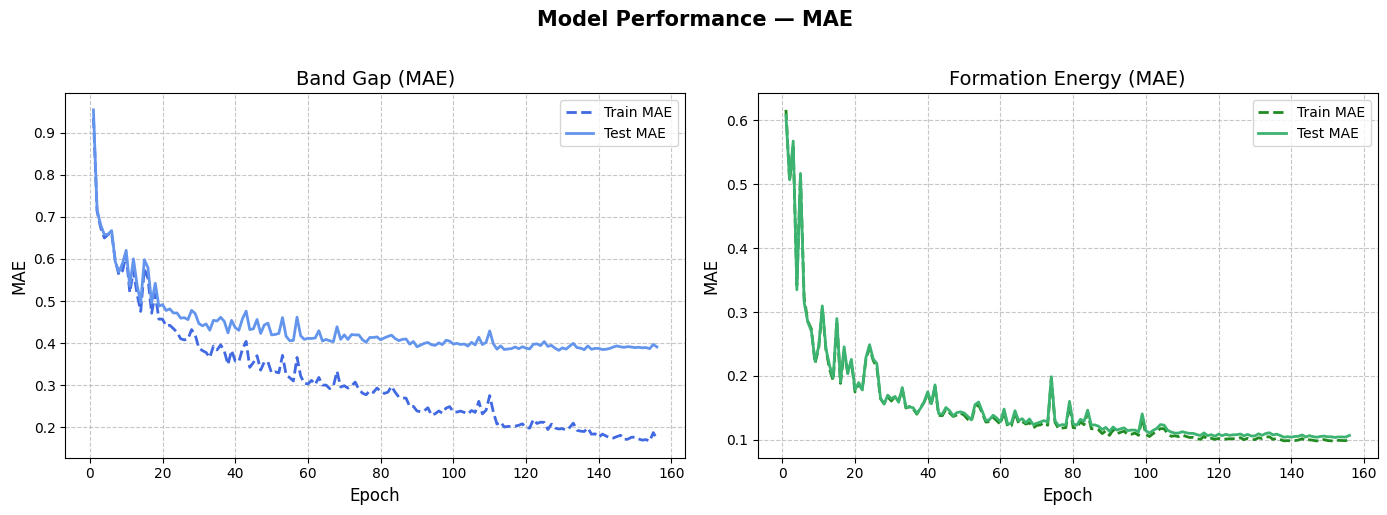

In [6]:
graph_metric('mae')

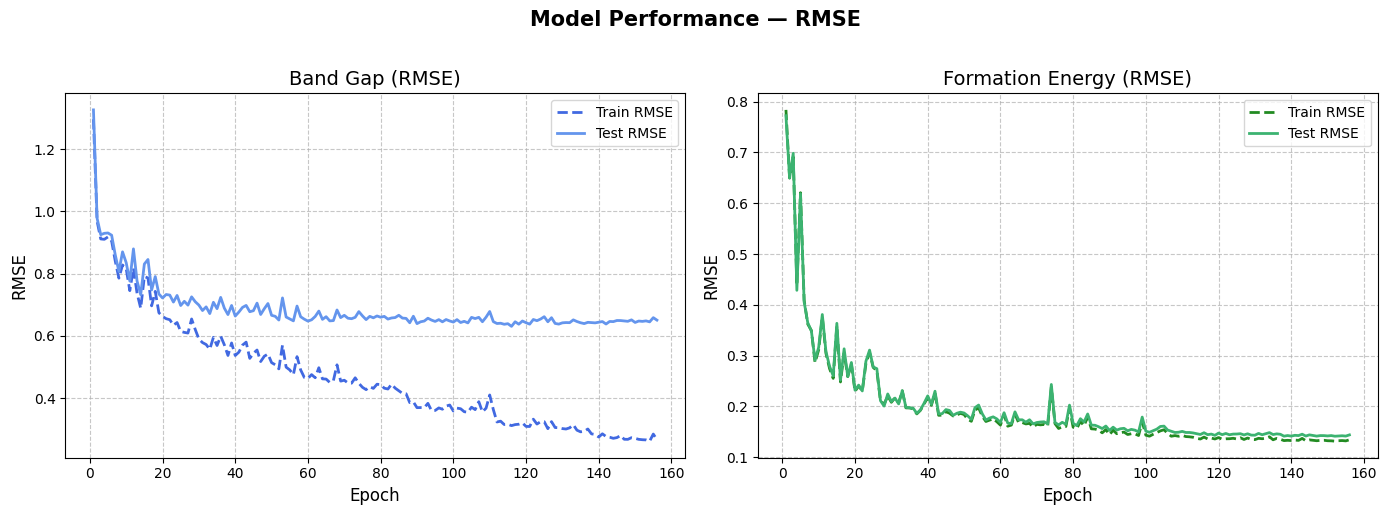

In [7]:
graph_metric('rmse')

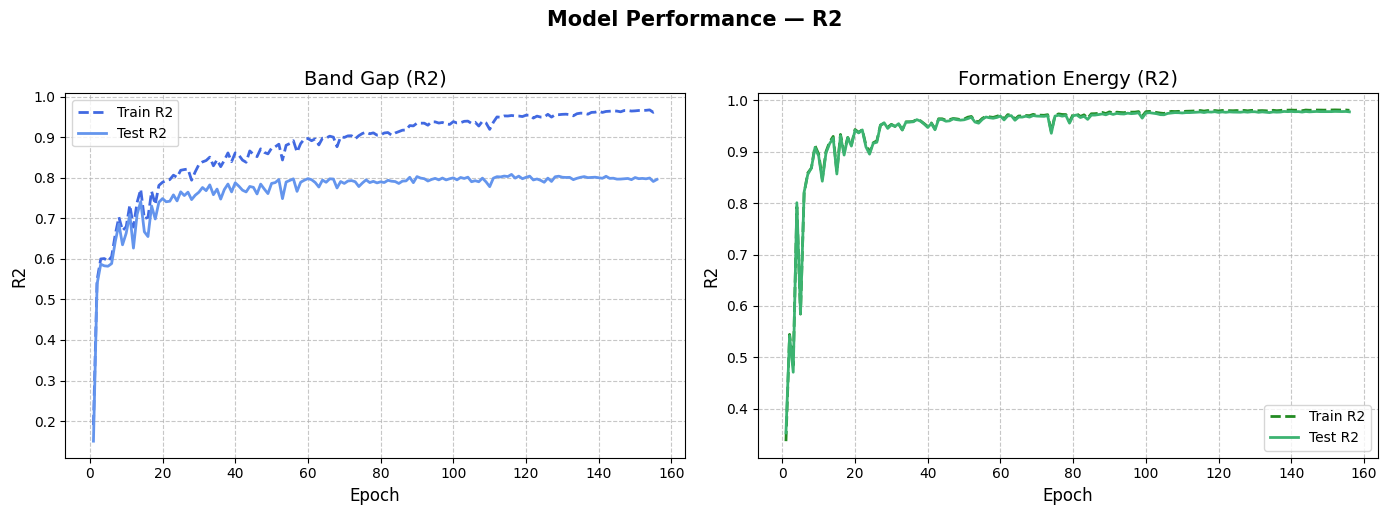

In [8]:
graph_metric('r2')

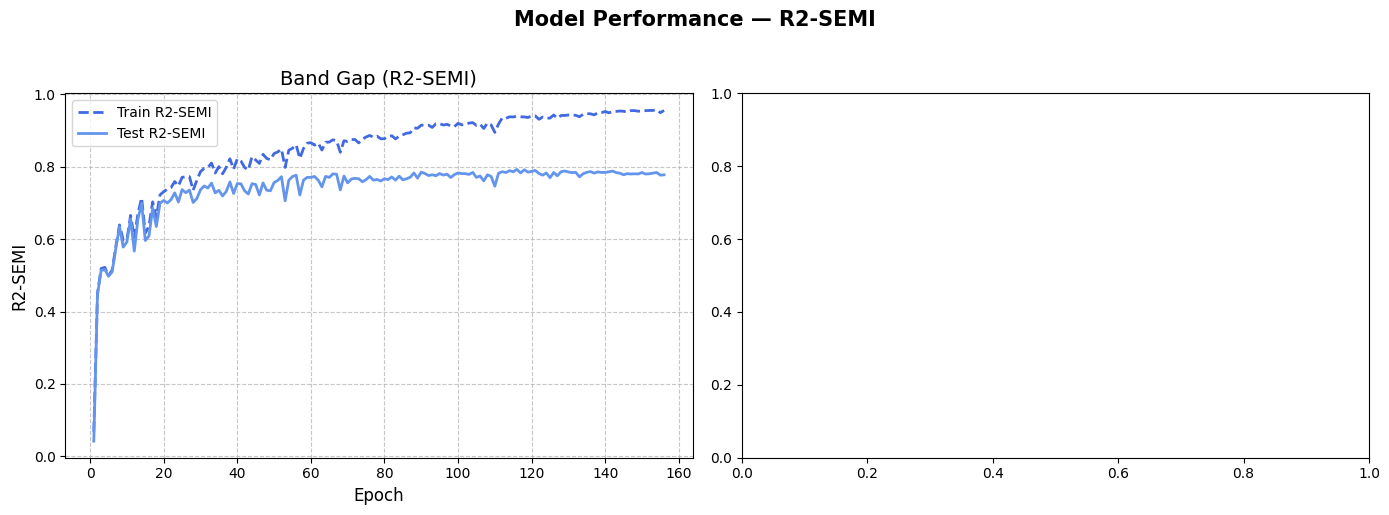

In [14]:
graph_metric('r2-semi')

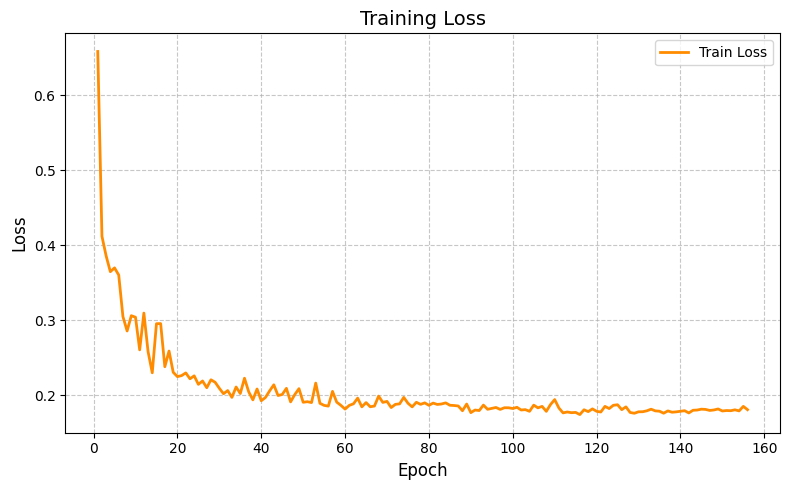

In [10]:
graph_loss()

In [11]:
def plot_scatter_with_fit(ax, x, y):
    all_vals = np.concatenate([x, y])
    lims = [min(all_vals.min(), 0), max(all_vals.max(), 1e-6)]
    
    ax.scatter(x, y, alpha=0.5, s=20, color="steelblue", zorder=2)
    ax.plot(lims, lims, "k--", linewidth=1, label="Ideal", zorder=3)

    m, b = np.polyfit(x, y, 1)
    x_fit = np.linspace(lims[0], lims[1], 200)
    ax.plot(x_fit, m * x_fit + b, "r-", linewidth=1.5, label=f"Fit: y={m:.2f}x+{b:.2f}", zorder=4)

    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.legend(fontsize=8)
    ax.set_aspect("auto", adjustable="box")

In [12]:
def plot_gnn_predictions(df_train, df_test, model_name="GNN Model"):
    """
    Plot actual vs predicted for band gap (bg) and formation energy (fe)
    for both train and test sets.
    
    Args:
        df_train: DataFrame with columns bg_actual, bg_predicted, fe_actual, fe_predicted
        df_test:  Same structure as df_train
        model_name: String label for plot titles
    """
    targets = [
        ("bg_actual",  "bg_predicted",  "Band Gap",         "eV"),
        ("fe_actual",  "fe_predicted",  "Formation Energy", "eV/atom"),
    ]
    splits = [("Train", df_train), ("Test", df_test)]

    fig, axes = plt.subplots(len(targets), len(splits), figsize=(14, 10))
    axes = np.atleast_2d(axes)  # shape: (n_targets, n_splits)

    for row_i, (actual_col, pred_col, target_name, unit) in enumerate(targets):
        for col_j, (split_name, df) in enumerate(splits):
            ax = axes[row_i, col_j]

            x = df[actual_col].to_numpy(dtype=float)
            y = df[pred_col].to_numpy(dtype=float)

            plot_scatter_with_fit(ax, x, y)

            # Metrics
            mae  = np.mean(np.abs(y - x))
            rmse = np.sqrt(np.mean((y - x) ** 2))
            r2   = 1 - np.sum((y - x) ** 2) / np.sum((x - x.mean()) ** 2)

            ax.set_title(
                f"{model_name} — {target_name} ({split_name})\n"
                f"MAE={mae:.4f}  RMSE={rmse:.4f}  R²={r2:.4f}",
                fontsize=10
            )
            ax.set_xlabel(f"Actual {target_name} ({unit})")
            ax.set_ylabel(f"Predicted {target_name} ({unit})")

    plt.tight_layout()
    plt.show()

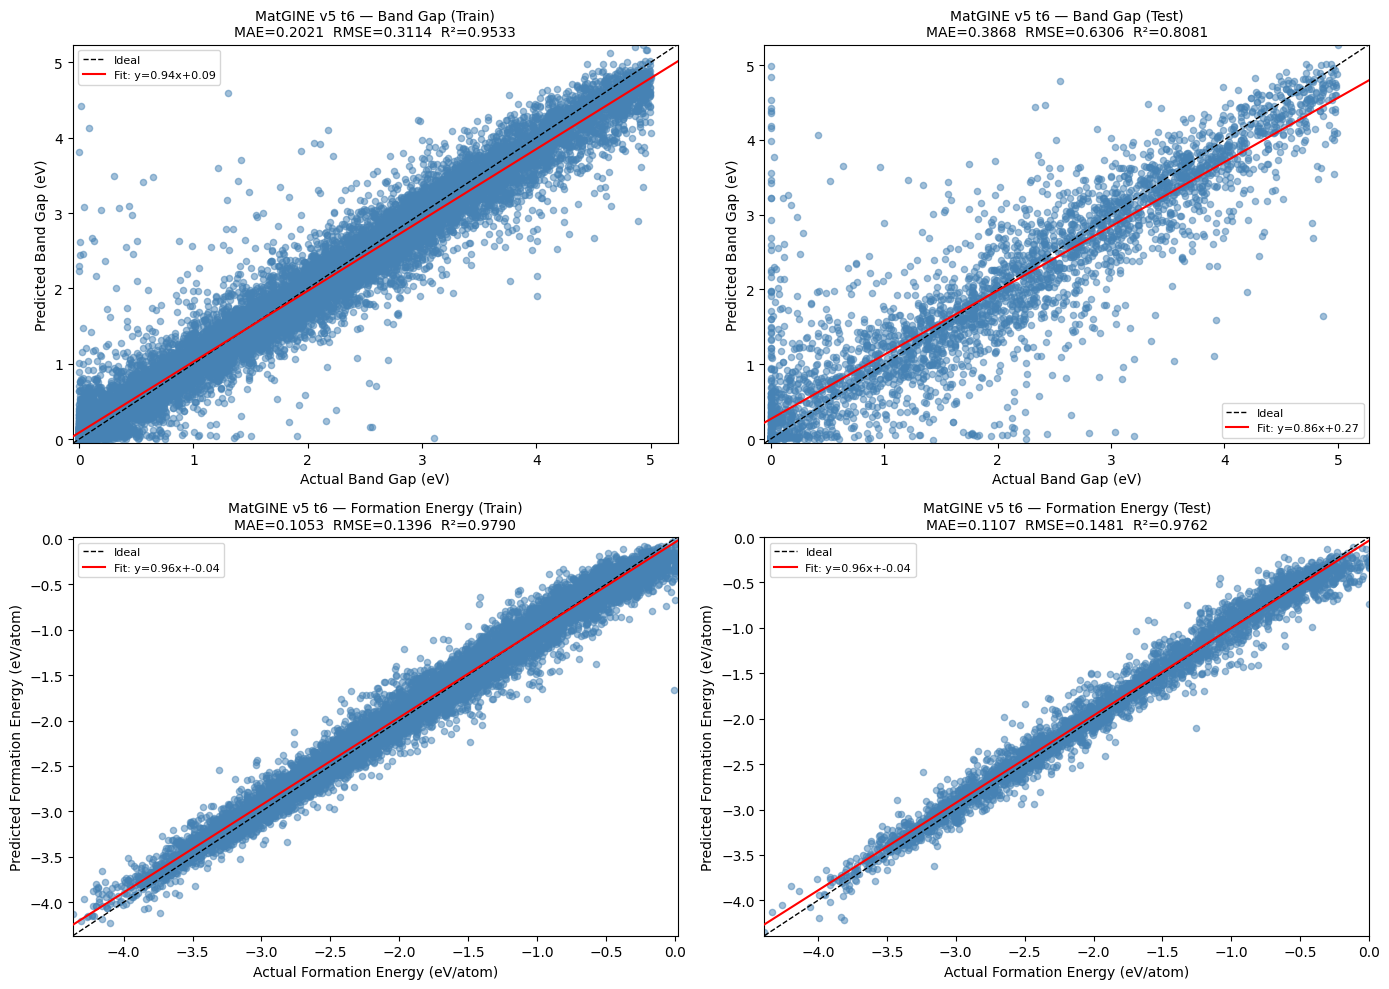

In [13]:
df_train = pd.read_csv(DATA_DIR / "train_predictions_vs_actuals.csv")
df_test  = pd.read_csv(DATA_DIR / "test_predictions_vs_actuals.csv")

plot_gnn_predictions(df_train, df_test, model_name=f"MatGINE v{model_number} t{trial_number}")

In [25]:
# Load metadata to get best epoch
with open(DATA_DIR / "metadata.json", "r") as f:
    metadata = json.load(f)

best_epoch = metadata["best_epoch"]

# Load results CSV and filter to best epoch
df = pd.read_csv(DATA_FILE, low_memory=False)

bg_test_cols = ["epoch", "test_bg_rmse", "test_bg_mae", "test_bg_r2", "test_bg_r2-semi"]
epoch_row = df[df["epoch"] == best_epoch][bg_test_cols]

best_metrics = epoch_row.to_dict(orient="records")[0]

print("Best Epoch")
for key in best_metrics:
    print(f"{key}: {best_metrics[key]:.4f}")

Best Epoch
epoch: 116.0000
test_bg_rmse: 0.6306
test_bg_mae: 0.3868
test_bg_r2: 0.8081
test_bg_r2-semi: 0.7930


In [26]:
df[[col for col in df.columns if "test_bg" in col]].describe()

,test_bg_rmse,test_bg_mae,test_bg_r2,test_bg_r2-semi
count,156.000000,156.000000,156.000000,156.000000
mean,0.687593,0.436891,0.768381,0.740899
std,0.084307,0.077992,0.070228,0.085417
min,0.630596,0.382870,0.150586,0.041912
25%,0.646743,0.393423,0.768891,0.735686
50%,0.658254,0.408799,0.790850,0.770863
75%,0.691946,0.448379,0.798101,0.781233
max,1.326551,0.954127,0.808057,0.793001


Use a logic gating effect that says if the species is classified as a metal, its band gap is 0.0eV automatically

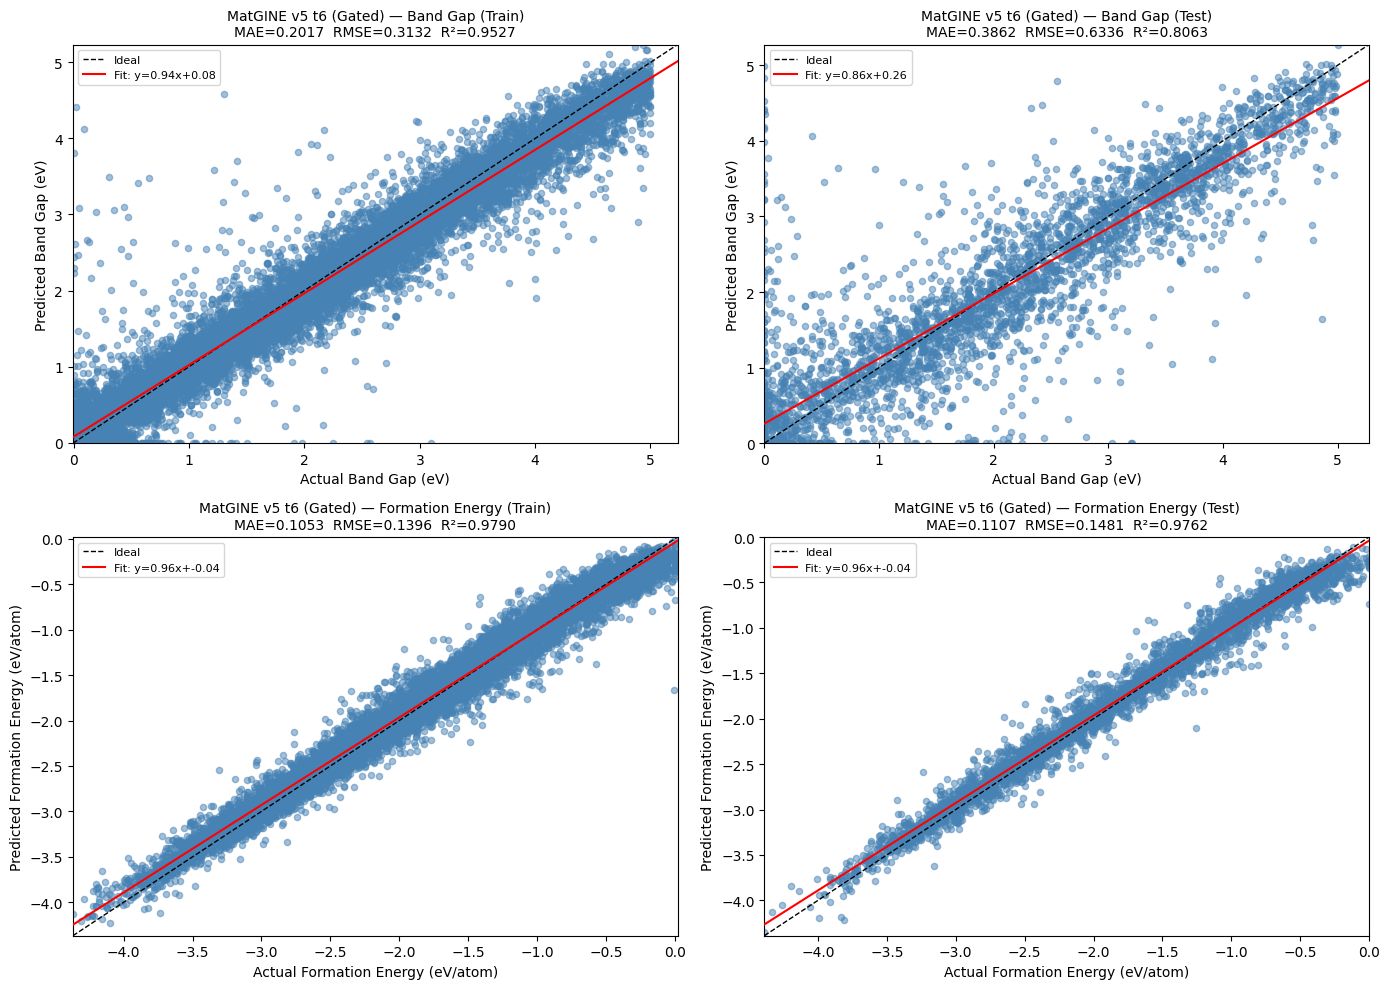

In [30]:
# 1. Create independent copies of your results
df_train_gated = df_train.copy()
df_test_gated = df_test.copy()

# 2. Apply the "Metal Gate" logic: If the model predicts a metal (1), force BG to 0.0
# This targets those 4-5eV outliers where the model predicted a metal.
df_train_gated.loc[df_train_gated['metal_predicted'] == 1, 'bg_predicted'] = 0.0
df_test_gated.loc[df_test_gated['metal_predicted'] == 1, 'bg_predicted'] = 0.0

# 3. Plot the results with your abstracted function
plot_gnn_predictions(
    df_train_gated, 
    df_test_gated, 
    model_name=f"MatGINE v{model_number} t{trial_number} (Gated)"
)

In [31]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [32]:
def print_metrics(df, label):
    y_true = df['bg_actual']
    y_pred = df['bg_predicted']
    
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    
    # R2 Semi (Calculated only on actual semiconductors)
    semi_mask = y_true > 0
    r2_semi = r2_score(y_true[semi_mask], y_pred[semi_mask])
    
    print(f"--- {label} Metrics ---")
    print(f"MAE:  {mae:.4f} eV")
    print(f"RMSE: {rmse:.4f} eV")
    print(f"R2:   {r2:.4f}")
    print(f"R2-Semi: {r2_semi:.4f}\n")

# Compare
print_metrics(df_test, "Original")
print_metrics(df_test_gated, "Gated (Metal-Corrected)")

--- Original Metrics ---
MAE:  0.3868 eV
RMSE: 0.6306 eV
R2:   0.8081
R2-Semi: 0.7930

--- Gated (Metal-Corrected) Metrics ---
MAE:  0.3862 eV
RMSE: 0.6336 eV
R2:   0.8063
R2-Semi: 0.7904

